# Transition rehearsal — five-seed analysis

Analyze the **abrupt / gradual-bridge / late-Binding** continuations from a common step-6,300 checkpoint. Primary: fixed-final Binding accuracy and task retention; secondary: transfer, learning dynamics and per-question errors. All task exposures are matched, but the task order differs. No retraining here.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
OUT_REL = Path("outputs/medium_world/experiments/transition_rehearsal/five_seeds")
DATA_REL = Path("outputs/medium_world/dataset")
OUT_DIR, DATA_DIR = PROJECT_ROOT / OUT_REL, PROJECT_ROOT / DATA_REL
RESULTS_FILE = OUT_DIR / "schedule_comparison.json"
SEEDS = [42,43,44,45,46]
STRATEGIES = ("abrupt", "gradual_bridge", "late_binding")
CHECKPOINTS = (6300,6600,7200,7300,9000)

In [2]:
import json, math, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.medium_visual_world.generate import read_jsonl
from src.medium_visual_world.prediction_tracking import (
    load_trace, compare_two, compare_three, summarize_changes, scene_context
)

report=json.loads(RESULTS_FILE.read_text(encoding="utf-8"))
assert report["config"]["strategies"] == list(STRATEGIES)
assert report["config"]["prefix_steps"] == 6300 and report["config"]["total_steps"] == 9000
for name,digest in report["dataset_hashes"].items():
    assert hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest() == digest
runs=sorted(report["runs"],key=lambda r:(r["seed"],r["schedule"]))
assert {(r["seed"],r["schedule"]) for r in runs} == {(s,c) for s in SEEDS for c in STRATEGIES}
assert len(runs) == len(SEEDS)*len(STRATEGIES)
traces={}
for r in runs:
    assert r["steps_run"] == 9000 and r["status"] == "completed" and len(r["history"]) == 91
    t=load_trace(OUT_DIR/r["prediction_trace"])
    assert t["metadata"]["parent_sha256"] == r["parent_sha256"]
    for split,n in (("id_dev",1024),("ood_dev",400)):
        b=t["splits"][split]
        assert b["predictions"].shape == (91,n)
        assert np.array_equal(b["steps"],np.arange(0,9001,100))
    traces[(r["seed"],r["schedule"])]=t
assert all(len({r["parent_sha256"] for r in runs if r["seed"] == seed}) == 1 for seed in SEEDS)
for seed in SEEDS:
    reference=traces[(seed,STRATEGIES[0])]
    for strategy in STRATEGIES[1:]:
        current=traces[(seed,strategy)]
        for split in ("id_dev","ood_dev"):
            assert np.array_equal(reference["splits"][split]["predictions"][:64],
                                  current["splits"][split]["predictions"][:64])
            assert np.array_equal(reference["splits"][split]["probabilities"][:64],
                                  current["splits"][split]["probabilities"][:64])
print("PASS:",len(runs),"runs, 5 shared parent states, identical prefix traces, dataset hashes verified")

PASS: 15 runs, 5 shared parent states, identical prefix traces, dataset hashes verified


## Fixed-endpoint results and paired uncertainty

The primary endpoint is step 9,000. Report all five seed-level results; paired intervals use a t critical value for four degrees of freedom. **Step 7,200 is not exposure-matched across strategies** and should be treated as a learning-trajectory checkpoint, not as the primary comparison.

In [ ]:
final_rows=[]
for r in runs:
    for step in CHECKPOINTS:
        h=next(h for h in r["history"] if h["step"]==step)
        for split in ("id_dev","ood_dev"):
            b=h[split]["binary_by_template"]["pair"]
            final_rows.append({"seed":r["seed"],"strategy":r["schedule"],"step":step,
                               "split":split,"accuracy":h[split]["by_template"]["pair"],
                               "cross_entropy":h[split]["loss_by_template"]["pair"],
                               "positive_recall":b["positive_recall"],
                               "negative_specificity":b["negative_specificity"],
                               "predicted_positive_rate":b["predicted_positive_rate"],
                               "tp":b["tp"],"fn":b["fn"],"tn":b["tn"],"fp":b["fp"]})
endpoints=pd.DataFrame(final_rows)
endpoints.to_csv(OUT_DIR/"binding_endpoints.csv",index=False)
end= endpoints[endpoints.step==9000]
summary=end.groupby(["strategy","split"],as_index=False).agg(
    accuracy_mean=("accuracy","mean"),accuracy_sd=("accuracy","std"),
    positive_recall=("positive_recall","mean"),negative_specificity=("negative_specificity","mean"))
display(summary)

comparisons=[("gradual_bridge","abrupt"),("late_binding","abrupt"),
             ("gradual_bridge","late_binding")]
paired=[]
for left,right in comparisons:
    for split in ("id_dev","ood_dev"):
        table=end[end.split==split].pivot(index="seed",columns="strategy",values="accuracy")
        d=(table[left]-table[right]).sort_index()
        mean=float(d.mean())
        sd=float(d.std(ddof=1))
        se=sd/np.sqrt(len(d))
        row={"left":left,"right":right, "split":split,"n_seeds":len(d),
             "mean_difference":mean, "sd_difference":sd,
             "ci95_low":mean-2.776445105*se, "ci95_high":mean+2.776445105*se,
             "wins":int((d>0).sum()), "ties":int((d==0).sum())}
        row.update({f"seed_{k}":float(v) for k,v in d.items()})
        paired.append(row)
paired=pd.DataFrame(paired)
paired.to_csv(OUT_DIR/"paired_differences.csv", index=False)
display(paired)

,strategy,split,accuracy_mean,accuracy_sd,positive_recall,negative_specificity
0,abrupt,id_dev,0.625000,0.018529,0.740625,0.509375
1,abrupt,ood_dev,0.572000,0.026949,0.672000,0.472000
2,gradual_bridge,id_dev,0.658594,0.026146,0.778125,0.539062
3,gradual_bridge,ood_dev,0.589000,0.026844,0.707000,0.471000
4,late_binding,id_dev,0.658594,0.020033,0.790625,0.526563
5,late_binding,ood_dev,0.596000,0.023888,0.726000,0.466000


,left,right,split,n_seeds,mean_difference,sd_difference,ci95_low,ci95_high,wins,ties,seed_42,seed_43,seed_44,seed_45,seed_46
0,gradual_bridge,abrupt,id_dev,5,0.033594,0.017600,0.011741,0.055447,5,0,0.039062,0.035156,0.003906,0.050781,0.039062
1,gradual_bridge,abrupt,ood_dev,5,0.017000,0.020646,-0.008635,0.042635,4,0,0.027500,0.045000,-0.007500,0.017500,0.002500
2,late_binding,abrupt,id_dev,5,0.033594,0.018028,0.011209,0.055979,5,0,0.042969,0.058594,0.011719,0.031250,0.023438
3,late_binding,abrupt,ood_dev,5,0.024000,0.030802,-0.014245,0.062245,5,0,0.022500,0.077500,0.010000,0.002500,0.007500
4,gradual_bridge,late_binding,id_dev,5,0.000000,0.017686,-0.021960,0.021960,2,0,-0.003906,-0.023438,-0.007812,0.019531,0.015625
5,gradual_bridge,late_binding,ood_dev,5,-0.007000,0.018658,-0.030167,0.016167,2,0,0.005000,-0.032500,-0.017500,0.015000,-0.005000


## Learning trajectories and retained Binding

Plot accuracy around the branch and across the suffix. The curves should coincide through step 6,300 within each seed. We also record Binding presentations accumulated by each checkpoint.

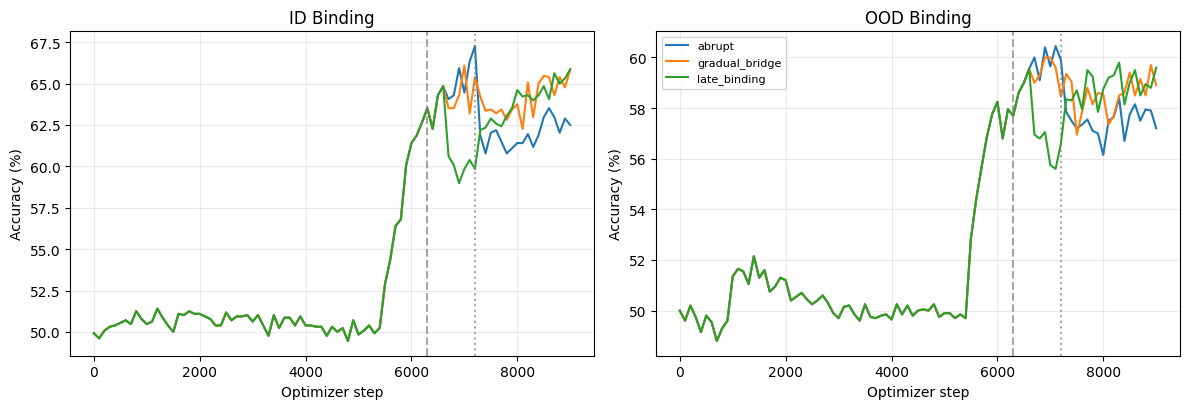

Final presentations:


,binding_presentations
strategy,
abrupt,112500.0
gradual_bridge,112500.0
late_binding,112500.0


In [ ]:
curves=[]
for r in runs:
    for h in r["history"]:
        counts=h["cumulative_task_presentations"]
        curves.append({"seed":r["seed"],"strategy":r["schedule"],"step":h["step"],
                       "binding_presentations":counts.get("pair",0),
                       "id_binding":h["id_dev"]["by_template"]["pair"],
                       "ood_binding":h["ood_dev"]["by_template"]["pair"],
                       **{f"id_{task}":h["id_dev"]["by_template"][task]
                          for task in ("color","shape","conjunction")}})
curves=pd.DataFrame(curves)
curves.to_csv(OUT_DIR/"binding_learning_curves.csv",index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
for strategy in STRATEGIES:
    avg=curves[curves.strategy==strategy].groupby("step")[["id_binding","ood_binding"]].mean()
    axs[0].plot(avg.index,100*avg.id_binding,label=strategy)
    axs[1].plot(avg.index,100*avg.ood_binding,label=strategy)
for ax,title in zip(axs,("ID Binding","OOD Binding")):
    ax.axvline(6300,color="grey",linestyle="--",alpha=.7)
    ax.axvline(7200,color="grey",linestyle=":",alpha=.7)
    ax.set(title=title,xlabel="Optimizer step",ylabel="Accuracy (%)")
    ax.grid(alpha=.25)
axs[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR/"binding_learning_curves.png", dpi=160)
plt.show()

phase_rows=[]
for r in runs:
    for p in r["phase_plan"]["phases"]:
        phase_rows.append({"seed":r["seed"],"strategy":r["schedule"],
                           "phase":p["phase"],"start":p["start_step"],"end":p["end_step"],
                           **{f"n_{t}":p["presentations_by_task"].get(t,0) for t in ("color","shape","conjunction","pair")}})
phase=pd.DataFrame(phase_rows)
phase.to_csv(OUT_DIR/"phase_exposure.csv",index=False)
print("Final presentations:")
display(curves[curves.step==9000].groupby("strategy")[["binding_presentations"]].mean())

## Retention, recovery, and prediction bias

Measure change over predefined windows: 6,300→9,000 (entire intervention), 7,200→7,300 (immediate shift), and 7,200→9,000 (later training). 'Forgotten' means correct→incorrect on the same question ID, not proof of a lost abstract concept. In particular, step-7,200 windows compare differing strategies at different Pair exposure counts.

In [5]:
windows=[(6300,9000),(6600,7200),(7200,7300),(7200,9000)]
change_rows=[]
for r in runs:
    t=traces[(r["seed"],r["schedule"])]
    for split in ("id_dev","ood_dev"):
        block=t["splits"][split]
        for before,after in windows:
            x=compare_two(block,before,after)
            for _,s in summarize_changes(x).iterrows():
                change_rows.append({"seed":r["seed"],"strategy":r["schedule"],
                                    "split":split,"before":before,"after":after,**s.to_dict()})
changes=pd.DataFrame(change_rows)
changes.to_csv(OUT_DIR/"prediction_change_summary.csv",index=False)
view=changes[(changes.task=="pair") & (changes.before==7200) & (changes.after==7300)]
display(view.groupby(["strategy","split"])[["accuracy_before","accuracy_after",
    "forgetting_rate","newly_learned_rate","correctness_churn"]].mean().round(3))

# For recovery we need three increasing checkpoints; 7,200→7,300→9,000.
recovery=[]
for r in runs:
    for split in ("id_dev","ood_dev"):
        t=traces[(r["seed"],r["schedule"])]["splits"][split]
        rec=compare_three(t,7200,7300,9000)
        for _,s in summarize_changes(rec).iterrows():
            recovery.append({"seed":r["seed"],"strategy":r["schedule"],"split":split,**s.to_dict()})
recovery=pd.DataFrame(recovery)
recovery.to_csv(OUT_DIR/"recovery_summary.csv",index=False)
display(recovery[recovery.task=="pair"].groupby(["strategy","split"])[
    ["forgetting_rate","recovery_rate_among_forgotten"]].mean().round(3))

accuracy_before  accuracy_after  forgetting_rate  \
strategy       split                                                       
abrupt         id_dev             0.673           0.619            0.181   
               ood_dev            0.599           0.578            0.190   
gradual_bridge id_dev             0.654           0.642            0.107   
               ood_dev            0.584           0.594            0.099   
late_binding   id_dev             0.598           0.622            0.120   
               ood_dev            0.566           0.584            0.095   

                        newly_learned_rate  correctness_churn  
strategy       split                                           
abrupt         id_dev                0.213              0.191  
               ood_dev               0.237              0.209  
gradual_bridge id_dev                0.165              0.127  
               ood_dev               0.163              0.125  
late_binding   id_dev                0.233              0.166  
               ood_dev               0.161              0.123

forgetting_rate  recovery_rate_among_forgotten
strategy       split                                                  
abrupt         id_dev             0.181                          0.505
               ood_dev            0.190                          0.336
gradual_bridge id_dev             0.107                          0.643
               ood_dev            0.099                          0.455
late_binding   id_dev             0.120                          0.384
               ood_dev            0.095                          0.322

## Final errors by held-out combination and scene complexity

Subgroups include true-label support and confusion counts. Scene attributes come from the frozen question/scene JSON and are joined using question IDs, avoiding different samples across curricula.

In [ ]:
metadata={split:list(read_jsonl(DATA_DIR/("id_dev.jsonl" if split=="id_dev" else "ood_dev.jsonl")))
          for split in ("id_dev","ood_dev")}
subgroups=[]
for r in runs:
    for split in ("id_dev","ood_dev"):
        b=traces[(r["seed"],r["schedule"])]["splits"][split]
        labels=b["labels"]
        pred=b["predictions"][-1]
        df=pd.DataFrame({"example_id":b["ids"],"task":b["tasks"],"label":labels,"prediction":pred})
        df=scene_context(df,metadata[split])
        df=df[df.task=="pair"].copy()
        for attribute in ("target_color","target_shape","n_objects","n_colors","n_shapes"):
            for value,part in df.groupby(attribute):
                y,p=part.label.to_numpy(),part.prediction.to_numpy()
                tp=int(((p==1)&(y==1)).sum())
                fn=int(((p==0)&(y==1)).sum())
                tn=int(((p==0)&(y==0)).sum())
                fp=int(((p==1)&(y==0)).sum())
                subgroups.append({"seed":r["seed"],"strategy":r["schedule"],"split":split,
                                  "attribute":attribute,"value":value,"n":len(part),
                                  "positive_n":int((y==1).sum()),"negative_n":int((y==0).sum()),
                                  "tp":tp,"fn":fn,"tn":tn,"fp":fp,
                                  "accuracy":(tp+tn)/len(part)})
            if attribute=="target_shape":
                df["pair_label"]=df.target_color+"–"+df.target_shape
                for value,part in df.groupby("pair_label"):
                    y,p=part.label.to_numpy(),part.prediction.to_numpy()
                    tp=int(((p==1)&(y==1)).sum())
                    fn=int(((p==0)&(y==1)).sum())
                    tn=int(((p==0)&(y==0)).sum())
                    fp=int(((p==1)&(y==0)).sum())
                    subgroups.append({"seed":r["seed"],"strategy":r["schedule"],"split":split,
                                      "attribute":"target_pair","value":value,"n":len(part),
                                      "positive_n":int((y==1).sum()),"negative_n":int((y==0).sum()),
                                      "tp":tp,"fn":fn,"tn":tn,"fp":fp,
                                      "accuracy":(tp+tn)/len(part)})
subgroups=pd.DataFrame(subgroups)
subgroups.to_csv(OUT_DIR/"prediction_error_subgroups.csv",index=False)
ex=subgroups[(subgroups.split=="ood_dev")&(subgroups.attribute=="target_pair")]
display(ex.groupby(["strategy","value"])[["n","positive_n","negative_n","tp","fn","tn","fp"]]
        .sum().assign(accuracy=lambda x:(x.tp+x.tn)/x.n).round(3))

n  positive_n  negative_n   tp   fn   tn  \
strategy       value                                                         
abrupt         blue–square      485         240         245  193   47  100   
               green–circle     545         275         270  219   56  135   
               purple–triangle  555         280         275  153  127  137   
               red–crescent     415         205         210  107   98  100   
gradual_bridge blue–square      485         240         245  202   38   97   
               green–circle     545         275         270  222   53  146   
               purple–triangle  555         280         275  165  115  128   
               red–crescent     415         205         210  118   87  100   
late_binding   blue–square      485         240         245  209   31   96   
               green–circle     545         275         270  232   43  146   
               purple–triangle  555         280         275  173  107  114   
               red–crescent     415         205         210  112   93  110   

                                 fp  accuracy  
strategy       value                           
abrupt         blue–square      145     0.604  
               green–circle     135     0.650  
               purple–triangle  138     0.523  
               red–crescent     110     0.499  
gradual_bridge blue–square      148     0.616  
               green–circle     124     0.675  
               purple–triangle  147     0.528  
               red–crescent     110     0.525  
late_binding   blue–square      149     0.629  
               green–circle     124     0.694  
               purple–triangle  161     0.517  
               red–crescent     100     0.535